# 6장 생성 모델 입문 — [실습] DCGAN으로 손글씨 숫자 만들기

오늘 직접 만드는 것 3가지

| | 하는 일 | 구성 |
|---|---|---|
| ① 생성자 Generator (셀 2) | 잡음 64개 → 28×28 숫자 그림 | 전치합성곱 3층으로 1×1 → 28×28 키우기 |
| ② 판별자 Discriminator (셀 3) | 그림 1장 → 진짜일 확률 0~1 | 합성곱 2층으로 28×28 → 7×7 줄이기 |
| ③ 번갈아 학습 (셀 5) | 판별자 한 걸음, 생성자 한 걸음 반복 | 5 에폭 뒤 생성자가 만든 16장 확인 (셀 6) |

**생성자와 판별자 한눈에 보기**

| | 생성자 G (셀 2) | 판별자 D (셀 3) |
|---|---|---|
| 하는 일 | 잡음 z에서 가짜 그림 만들기 | 그림이 진짜인지 가짜인지 판정 |
| 입력 | (B, 64, 1, 1) — 정규분포 잡음 | (B, 1, 28, 28) — 진짜 또는 가짜 그림 |
| 출력 | (B, 1, 28, 28) — 값 범위 -1 ~ 1 (Tanh) | (B, 1) — 진짜일 확률 0 ~ 1 (Sigmoid) |
| 부품 | ConvTranspose2d ×3 + BatchNorm + ReLU | Conv2d ×2 + BatchNorm + LeakyReLU + Linear |
| 크기 변화 | 1 → 7 → 14 → 28 (키우기) | 28 → 14 → 7 → 숫자 1개 (줄이기) |
| 원하는 것 | D가 내 그림을 진짜(1)라고 하게 | 진짜는 1, 가짜는 0으로 맞히게 |
| 손실 (셀 4·5) | BCELoss(D(G(z)), 1) | BCELoss(D(x), 1) + BCELoss(D(G(z)), 0) |

학습 루프(셀 5)는 4장과 같은 5줄을 두 번 씁니다 — 판별자 한 번, 생성자 한 번
`zero_grad()` → `model(...)` → `criterion(...)` → `loss.backward()` → `optimizer.step()`

## 개념 · 데이터 매니폴드 — 그림은 얇은 판 위에만 있다

- 28×28 그림은 숫자 784개. 아무렇게나 채우면 거의 다 잡음이고, **숫자처럼 보이는 조합만 얇은 판(매니폴드)처럼 모여 있음**
- 판 위에서 가까운 점끼리는 비슷한 그림, 판을 벗어나면 그림이 아닌 잡음
- 고양이 그림, 얼굴 그림처럼 종류마다 따로 판이 있음 → 전체 데이터는 이런 판 여러 장이 놓인 모양

**생성 모델이 하는 일**: 판이 어디 있는지 배워서, 판 위의 점 하나를 골라 그림으로 바꾸는 것. 판 위를 찍으면 그림, 판 밖을 찍으면 잡음.

## 개념 · 생성 모델의 뼈대 — 인코더와 디코더

- **인코더** — 그림 x를 짧은 숫자 묶음 z(잠재 벡터)로 줄임. **디코더** — z만 보고 그림 x′을 다시 만듦
- z가 사는 곳이 **잠재 공간**. 잠재 공간의 점 하나 = 그림 한 장
- 가운데가 좁은 이유: 그림을 그대로 복사할 수 없게 해서 요점만 z에 담게 함 ("숫자 7, 조금 기울어짐, 굵은 획")
- 생성 모델은 모두 이 디코더를 가짐 → **오늘 코드의 생성자(셀 2)가 디코더**

| 모델 | 방식 |
|---|---|
| VAE | 인코더로 그림을 z로 줄이고, 디코더로 되살림 |
| GAN | 인코더가 없음. 판별자 D가 진짜/가짜(1/0)를 가리고, 생성자 G가 z로 가짜를 만듦 |
| 디퓨전 | 그림에 잡음을 조금씩 더했다가 거꾸로 걷어냄 (9장) |

셋 다 데이터가 모인 판(매니폴드)을 배워서 판 위의 그림을 만듭니다. 오늘은 GAN을 만듭니다.

## 개념 · 오토인코더 (AE)

- 인코더(합성곱으로 줄이기) → z → 디코더(다시 키우기)가 한 줄로 이어진 하나의 신경망. 입력부터 출력까지 함께 학습
- **정답 라벨이 필요 없음** — 입력 그림 자체가 정답
- **복원 손실**: 입력 x와 되살린 x̂의 픽셀 차이 (4장의 MSE). 이 점수가 작아지도록 학습
- 응용: 잡음 제거(잡음 섞은 그림 → 깨끗한 원본), 이상 탐지(결함 부분을 되살리지 못해 차이로 드러남), 차원 축소
- **한계** — 되살리기는 잘하지만 새로 만들기는 약함. 학습한 그림마다 지도에 핀만 꽂은 상태라, 핀과 핀 사이의 빈 땅을 찍으면 이상한 그림이 나옴

오늘 코드와의 관계: 생성자(셀 2)는 디코더와 같은 모양, 판별자(셀 3)는 인코더와 같은 모양입니다. 단, GAN에는 복원 손실이 없고 대신 "판별자를 얼마나 속였나"가 점수입니다.

## 개념 · 변이형 오토인코더 (VAE)

- 인코더가 z를 바로 내지 않고 **평균 μ와 표준편차 σ**를 냄 → 그 작은 구름에서 z를 하나 뽑아 디코더로
- 학습 목표 ① 되살린 x′이 입력 x와 닮을 것 (복원 손실) ② 구름이 가운데에 모일 것 (KL 발산)
- 점 대신 구름 → 구름끼리 겹쳐 빈틈이 메워짐 → 아무 데나 찍어도 그림이 나옴 (연속적인 잠재 공간)
- 장점: 학습이 안정적, 확률로 해석 가능 · 단점: 그림이 흐릿한 편 · 확장: 조건부 VAE, VQ-VAE, 계층형 VAE

**VAE는 안정적이지만 흐릿하고, GAN은 선명하지만 학습이 까다롭습니다.** 오늘은 선명한 쪽인 GAN을 만듭니다.

## 개념 · GAN의 구조와 학습

- **생성자 G** — z를 받아 가짜 그림을 만듦. 목표: 판별자가 내 그림을 진짜라고 하게
- **판별자 D** — 진짜와 가짜를 모두 보고 가려냄. 한쪽이 잘하면 다른 쪽이 손해 (제로섬 게임)
- 비유: 위조지폐범(생성자)과 감별사(판별자). 끝에는 감별사도 구분 못 할 지폐가 나옴
- **미니맥스 게임**: 배치마다 판별자 한 걸음, 생성자 한 걸음을 번갈아 — 셀 5의 루프가 이 순서
- 이상적인 끝: 두 분포가 구별되지 않아 판별자가 반반(0.5)만 냄 = 내시 균형

**손실을 읽는 법**: 판별자 손실이 내려가면 생성자 손실은 올라갑니다. 손실 0을 기다리지 말고 셀 6의 생성 그림으로 판단하세요.

**GAN 학습의 한계와 WGAN**
- 판별자가 너무 세면 생성자가 고칠 방향을 얻지 못해 학습이 멈춤
- **모드 붕괴** — 생성자가 잘 속이는 한두 종류만 반복해 그림 (예: 1만 계속)
- WGAN — 흙더미 A를 B 모양으로 옮기는 총 이동량(Wasserstein 거리)을 써서 늘 방향을 알려 줌. 가중치 클리핑 → WGAN-GP로 안정화
- 오늘은 기본 GAN 손실(BCELoss). 과제 3(학습률 10배)과 과제 4(BatchNorm 제거)에서 판별자 과강·모드 붕괴를 직접 볼 수 있음

**DCGAN** = GAN을 합성곱으로 만든 것. 오늘 코드는 MNIST 28×28 흑백용 축소판 (생성자 전치합성곱 3층, 판별자 합성곱 2층)
4장 CNN은 줄이기만, 생성자는 키우기만 합니다. 출력이 클래스가 아니라 그림(1×28×28)이고, 마지막이 Softmax가 아니라 Tanh입니다.

## [프로그램 6-1] 데이터로더 구성하기

In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor(),     # (H, W, C) → (C, H, W), 값 범위 [0,1]
    transforms.Normalize((0.5,), (0.5,))    # [0,1] → [-1,1]로 정규화
])

dataset = datasets.MNIST(
    root='data',
    train=True,
    transform=transform,
    download=True
)

loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=True
)

### 셀 1 설명 — 값 범위를 -1 ~ 1로

흐름: 원본 픽셀 0 ~ 255 → `ToTensor` 0 ~ 1 → `Normalize` -1 ~ 1

- `Normalize((0.5,), (0.5,))` — (값 − 0.5) ÷ 0.5. 흑백이라 채널 1개 → 괄호 안 숫자도 1개
- 4장 분류에서는 0~1로 두어도 됐지만, GAN에서는 생성자 출력이 Tanh(−1 ~ 1)라서 진짜 그림도 같은 범위로 맞춤

**범위가 다르면** 판별자가 "값 범위"만 보고 진짜·가짜를 가려 버려 생성자가 배울 게 없어집니다. 셀 2의 Tanh와 이 줄은 한 쌍입니다.

**MNIST와 DataLoader**
- `datasets.MNIST` — 손글씨 숫자 60,000장(학습용). `download=True`면 처음 한 번 내려받음 (약 10MB)
- `batch_size=64` → 60,000 ÷ 64 = 938 배치가 한 에폭. `shuffle=True`로 매 에폭 순서 섞기
- 라벨(0~9)은 받지만 쓰지 않음 — 셀 5의 `for real_imgs, _ in loader`에서 `_`로 버림

**GAN은 라벨이 필요 없다**: "무엇인지"가 아니라 "진짜처럼 보이는지"만 배우기 때문입니다. 숫자 하나를 골라 만들고 싶다면 조건부 GAN(라벨을 입력에 같이 넣기)이 필요합니다.

## [프로그램 6-2] 생성자 네트워크 구성하기

In [2]:
import torch.nn as nn

class Generator(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.model = nn.Sequential(
            # 입력: (B, latent_dim, 1, 1)
            nn.ConvTranspose2d(latent_dim, 128, kernel_size=7, stride=1, padding=0),  # → (B,128,7,7)
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),          # → (B,64,14,14)
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),            # → (B,1,28,28)
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)

generator = Generator()

### 셀 2 설명 — 1×1을 7×7로 키우는 첫 층

- `latent_dim=64` — 잡음 z의 길이. 입력 모양은 (B, 64, 1, 1): 채널 64개짜리 1×1 "그림"
- `ConvTranspose2d(64, 128, kernel_size=7, stride=1, padding=0)` — 1×1을 7×7로: (1−1)×1 − 0 + 7 = 7
- `BatchNorm2d(128)` → `ReLU()` — 층마다 값을 고르게 정규화하고 음수 제거. DCGAN 논문의 기본 조합

**전치합성곱 = 합성곱을 거꾸로**: 합성곱이 kernel 7로 7×7을 1×1로 줄이듯, 전치합성곱은 1×1을 7×7로 펼칩니다. 학습되는 가중치가 있는 "키우기" 층입니다 (5장 U-Net의 interpolate는 가중치 없음).

**두 배씩 키우기 7 → 14 → 28**
- `kernel_size=4, stride=2, padding=1` — 크기가 정확히 2배: (7−1)×2 − 2 + 4 = 14, (14−1)×2 − 2 + 4 = 28
- 채널은 128 → 64 → 1로 줄어듦: 키울수록 채널 수는 줄여 마지막에 흑백 1채널 그림
- 마지막 층 뒤에는 BatchNorm·ReLU가 없고 Tanh만 — 출력값이 −1 ~ 1이 되어 셀 1의 Normalize와 맞음

흐름: z (64,1,1) → ConvT (128,7,7) → ConvT (64,14,14) → ConvT (1,28,28)

**왜 4·2·1인가**: stride 2에 kernel 4·padding 1이면 정확히 2배가 되어 DCGAN 표준이 됐습니다. kernel 3이면 2배−1 (예: 13)이라 28을 만들 수 없습니다.

**forward와 모델 만들기**
- `forward(self, z)` — nn.Sequential이라 한 줄: z를 넣으면 세 층을 차례로 지나 그림이 나옴
- `generator = Generator()` — 기본값 latent_dim=64로 생성. 셀 4의 `latent_dim = 64`와 같아야 셀 5의 z 모양이 맞음
- 파라미터 수 534,081 (판별자 138,817의 약 4배) — 그림을 "그리는" 쪽이 더 큼

| 층 | 출력 모양 (B 생략) | 가중치 모양 |
|---|---|---|
| ConvT 7×7 | (128, 7, 7) | (64, 128, 7, 7) |
| ConvT 4×4 s2 | (64, 14, 14) | (128, 64, 4, 4) |
| ConvT 4×4 s2 | (1, 28, 28) | (64, 1, 4, 4) |

확인: `generator(torch.randn(2, 64, 1, 1)).shape` → `[2, 1, 28, 28]`

## [프로그램 6-3] 판별자 네트워크 구성하기

In [3]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # 입력: (B,1,28,28)
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),     # → (B,64,14,14)
            nn.LeakyReLU(0.2),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),   # → (B,128,7,7)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),

            nn.Flatten(),                                             # → (B,128*7*7)
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

discriminator = Discriminator()

### 셀 3 설명 — 합성곱으로 28 → 14 → 7 줄이기

- `Conv2d(1, 64, kernel_size=4, stride=2, padding=1)` — 4장 공식 (28 + 2 − 4) ÷ 2 + 1 = 14. 생성자의 거울상
- `LeakyReLU(0.2)` — 음수를 0이 아니라 0.2배로 남김. 판별자의 기울기가 죽지 않게 하는 DCGAN 관례
- 첫 층에는 BatchNorm이 없고 둘째 층부터 있음 — 입력 그림의 진짜·가짜 통계를 첫 층에서 지우지 않기 위해

**ReLU와 LeakyReLU**: ReLU는 음수를 모두 0으로 → 그 뉴런은 학습 신호가 0. LeakyReLU는 작은 기울기(0.2)를 남겨 판별자가 "죽은 뉴런" 없이 계속 배웁니다. 생성자는 ReLU 그대로 (셀 2).

**펼쳐서 확률 하나로**
- `Flatten()` — (B, 128, 7, 7)을 (B, 6272) 한 줄로. 4장 CNN의 분류기 앞과 같음
- `Linear(128 * 7 * 7, 1)` — 6272 → 1: 점수 하나. `Sigmoid()`로 0 ~ 1의 "진짜일 확률"
- 출력 (B, 1) — 셀 5의 라벨 `torch.ones(batch_size, 1)`과 같은 모양

흐름: Conv 끝 (128,7,7) → Flatten (6272,) → Linear (1,) → Sigmoid 0 ~ 1

| | 4장 분류기 | 판별자 |
|---|---|---|
| 마지막 | Linear(…, 10) + Softmax | Linear(…, 1) + Sigmoid |
| 출력 | 10개 중 하나 | 진짜 확률 하나 |

## [프로그램 6-4] 이진 교차 엔트로피 손실과 Adam 최적화 기법을 설정하기

In [4]:
criterion = nn.BCELoss()

optimizer_G = torch.optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = torch.optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

latent_dim = 64

### 셀 4 설명 — BCELoss와 옵티마이저 두 개

- `BCELoss()` — 이진 교차 엔트로피. 확률(0~1)과 정답(0 또는 1)을 비교. 5장 U-Net과 같은 손실
- **옵티마이저가 두 개** — `optimizer_G`는 생성자 파라미터만, `optimizer_D`는 판별자 파라미터만 갱신. 서로의 가중치는 건드리지 않음
- `betas=(0.5, 0.999)` — Adam의 모멘텀을 기본 0.9에서 0.5로. GAN은 목표가 계속 움직여서 관성이 크면 진동함 (DCGAN 논문 권장값)
- `latent_dim = 64` — 셀 5·6에서 z를 만들 때 씀. 셀 2 `Generator(latent_dim=64)`와 반드시 같은 값

**lr=0.0002**: 4장의 0.001보다 작습니다. 두 네트워크가 번갈아 움직이므로 한 번에 크게 가면 균형이 깨집니다.

## [프로그램 6-5] 이진 교차 엔트로피 손실을 이용한 GAN 학습 과정

In [5]:
num_epochs = 5
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generator.to(device)
discriminator.to(device)

for epoch in range(num_epochs):
    for real_imgs, _ in loader:
        real_imgs = real_imgs.to(device)      # (B,1,28,28)
        batch_size = real_imgs.size(0)

        # 1. 판별자 학습 단계
        optimizer_D.zero_grad()

        # 진짜 이미지에 대한 판별 결과와 손실
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        d_real = discriminator(real_imgs)
        loss_real = criterion(d_real, real_labels)

        # 생성된 가짜 이미지에 대한 판별 결과와 손실
        z = torch.randn(batch_size, latent_dim, 1, 1).to(device)
        fake_imgs = generator(z)
        d_fake = discriminator(fake_imgs.detach())
        loss_fake = criterion(d_fake, fake_labels)

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()

        # 2. 생성자 학습 단계
        optimizer_G.zero_grad()

        d_fake = discriminator(fake_imgs)
        loss_G = criterion(d_fake, real_labels)   # 생성자는 가짜를 진짜처럼 보이게 만들고자 함
        loss_G.backward()
        optimizer_G.step()

    print(f"Epoch {epoch+1}: D={loss_D.item():.4f}, G={loss_G.item():.4f}")

Epoch 1: D=0.4374, G=1.5590


Epoch 2: D=0.4589, G=1.6079


Epoch 3: D=0.6419, G=1.2821


Epoch 4: D=0.5235, G=2.5594


Epoch 5: D=0.7336, G=2.4731


### 셀 5 설명 — 준비: 장치, 배치, 정답 라벨

- `.to(device)`를 모델 2개와 데이터에 모두 — GPU 런타임이면 cuda, 아니면 cpu (CPU는 에폭당 약 1분)
- `for real_imgs, _ in loader` — 진짜 그림만 쓰고 라벨은 버림. `batch_size = real_imgs.size(0)`: 마지막 배치는 64가 아닐 수 있어 매번 셈
- `real_labels` = 1로 채운 (B,1), `fake_labels` = 0으로 채운 (B,1) — 판별자 출력 모양과 같게

**두 단계가 한 배치 안에서**: 배치마다 ① 판별자 한 걸음 → ② 생성자 한 걸음. 4장의 5줄 루프가 두 번 들어 있습니다.

**① 판별자 — 진짜는 1, 가짜는 0**
- `d_real = discriminator(real_imgs)` → `loss_real`: 진짜를 1이라 했는지
- `z = torch.randn(B, 64, 1, 1)` → `fake_imgs = generator(z)`: 지금 생성자가 만든 가짜 B장
- `fake_imgs.detach()` — 가짜를 "그냥 그림"으로 떼어 내서, 판별자 손실의 기울기가 생성자까지 흘러가지 않게 함
- `loss_D = loss_real + loss_fake` → `backward` → `optimizer_D.step()`: 판별자만 갱신

**detach()를 빼면** `loss_D.backward()`가 생성자에도 기울기를 남겨, 뒤의 생성자 단계에서 "가짜를 더 가짜답게" 만드는 쪽으로 섞입니다.

**② 생성자 — 가짜를 진짜라고 하게**
- `d_fake = discriminator(fake_imgs)` — 이번엔 detach() 없이: 기울기가 판별자를 지나 생성자까지 흘러야 함
- `criterion(d_fake, real_labels)` — 정답을 1(진짜)로 둠. "D가 내 가짜를 진짜라 하게"가 생성자의 목표
- `optimizer_G.step()` — 생성자만 갱신. 판별자에 쌓인 기울기는 다음 배치의 `zero_grad()`가 지움

흐름: z (randn) → G → fake_imgs → D → d_fake → BCE vs 1

**교재 식(6.10)과의 차이**: 식은 log(1 − D(G(z))) 최소화, 코드는 log D(G(z)) 최대화 (BCE를 1과 비교). 초반에 기울기가 더 커서 실전에서 쓰는 방식입니다.

**출력 읽기 — D와 G의 줄다리기**
- `print(...)` — 에폭이 끝날 때 마지막 배치의 손실만 찍음 (평균 아님). 숫자가 들쭉날쭉한 것이 정상
- D ≈ 1.4 (= 2 × ln 2)면 판별자가 반반으로 찍는 상태, 0에 가까우면 판별자가 완승 → 생성자가 배울 신호가 약해짐
- G가 올라가는 것은 판별자가 똑똑해졌다는 뜻. 둘이 번갈아 오르내리면 잘 되는 중

교재 출력 예 (CPU, 약 5분) — 실행마다 다름:
```
Epoch 1: D=0.6329, G=1.2056    ← 시작, 둘 다 반반 근처
Epoch 3: D=0.8790, G=1.8725    ← D가 앞서면 G 손실 ↑
Epoch 5: D=0.4204, G=2.2080    ← 우열은 셀 6 그림으로
```

**에폭 5에서 멈추는 이유**: 수업 시간 때문입니다. 20 에폭이면 획이 훨씬 또렷해집니다 (과제 1). GPU 런타임이면 에폭당 약 20초.

## [프로그램 6-6] 학습된 생성자를 이용해 이미지 샘플 생성 및 시각화하기

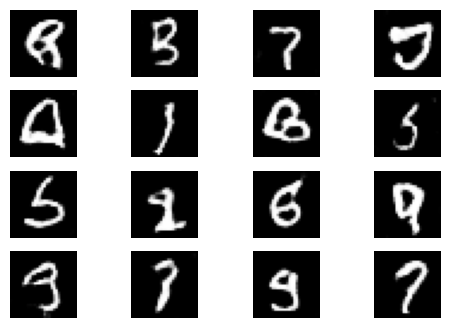

In [6]:
import matplotlib.pyplot as plt

generator.eval()
with torch.no_grad():
    z = torch.randn(16, latent_dim, 1, 1).to(device)
    samples = generator(z).cpu()

plt.figure(figsize=(6, 4))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(samples[i].squeeze(), cmap='gray')
    plt.axis("off")
plt.show()

### 셀 6 설명 — z 16개로 그림 16장

- `generator.eval()` — BatchNorm을 추론 모드로: 배치 통계 대신 학습 중 쌓아 둔 평균·분산 사용
- `torch.no_grad()` — 기울기 계산 끄기 (메모리·속도). 5장 U-Net의 결과 확인과 같은 패턴
- `z = torch.randn(16, latent_dim, 1, 1)` — 정규분포 잡음 16개 → samples 모양 (16, 1, 28, 28). `.cpu()`로 그림용으로 가져옴

**새 z = 새 숫자**: 셀을 다시 실행할 때마다 다른 16장. 같은 그림을 다시 보려면 위에 `torch.manual_seed(0)`.

**4×4 격자로 보기**
- `subplot(4, 4, i + 1)` — 4행 4열 중 i+1번째 칸. `samples[i].squeeze()`: (1,28,28) → (28,28)
- `cmap='gray'` — 값이 −1 ~ 1이지만 imshow가 최소~최대를 검정~흰색으로 알아서 늘림

흐릿하거나 깨진 숫자가 섞여 있는 것이 5 에폭의 정상 결과입니다. 전부 똑같은 모양이면 모드 붕괴 (과제 참고).

## 과제 · 직접 바꿔 보기 — 실습 1

1. **num_epochs = 5 → 20**: 셀 5의 1번 줄. 획이 얼마나 또렷해지나요? GPU 런타임 권장 (에폭당 약 20초)
2. **latent_dim 64 → 8**: 셀 2의 `Generator(latent_dim=8)`과 셀 4의 `latent_dim = 8` 둘 다 바꾸기. 숫자가 다양하게 나오나요?
3. **lr=0.0002 → 0.002**: 셀 4의 두 옵티마이저 모두. D·G 손실이 어떻게 튀는지, 그림이 무너지는지 보기
4. **BatchNorm 줄 지우기**: 셀 2의 `nn.BatchNorm2d` 두 줄을 지우기 (뒤의 쉼표 주의). 학습이 되는지 비교
5. **LeakyReLU(0.2) → ReLU()**: 셀 3의 두 줄. 판별자가 너무 강해지거나 멈추는지 관찰
6. **16장 → 64장**: 셀 6에서 `randn(64, …)`, `range(64)`, `subplot(8, 8, …)`로. 모드 붕괴(같은 숫자만 반복)가 보이나요?

한 번에 하나씩만 바꾸세요. 두 개를 같이 바꾸면 무엇 때문에 달라졌는지 알 수 없습니다.
셀 2·3·4를 바꿨으면 바꾼 셀부터 셀 6까지 순서대로 다시 실행 (셀 4를 건너뛰면 옵티마이저가 옛 모델을 붙잡고 있어 학습이 안 됨).

## 참고 · 실습 중 에러가 나면

| 에러 · 증상 | 원인 | 해결 |
|---|---|---|
| `RuntimeError: ... expected input[64, 64, 1, 1] to have 8 channels` | 셀 2의 latent_dim과 셀 4의 latent_dim이 다름 | 두 값을 같게 (과제 2) |
| `ValueError: Using a target size (torch.Size([64])) ...` | 라벨 모양이 (B,)인데 출력은 (B, 1) | `torch.ones(batch_size, 1)` 확인 |
| `RuntimeError: Expected all tensors to be on the same device` | 모델·데이터 중 하나만 GPU에 있음 | 셀 5의 `.to(device)` 여섯 군데 확인 |
| 숫자가 전부 같거나 회색 얼룩만 나옴 | 모드 붕괴 또는 학습 부족 | 에폭 늘리기 · lr 0.0002 유지 · BatchNorm 복구 |
| 에폭당 1분 넘게 걸림 | CPU 런타임 | 런타임 → 런타임 유형 변경 → T4 GPU, 셀 1부터 다시 |
| `RuntimeError: CUDA out of memory` | GPU 메모리 부족 (다른 노트북이 점유) | 런타임 재시작, 또는 batch_size 32 |
| 셀 6 그림이 처음 모양 그대로 | 셀 5를 안 돌리고 셀 6 실행 | 셀 5 실행 후 셀 6 (학습 전 생성자는 잡음만 그림) |